[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch08-short_workbook.ipynb)

# Three words, nine scores and the weights of `the`

Self-attention gives each of the words `the`, `cat` and `sat` a query, a key
and a value, three numbers each. How much does `the` attend to each word, and
what does dividing the scores by the square root of 3 change?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

WORDS = ["the", "cat", "sat"]
# The lecture's toy: three words of width 4, projected to queries, keys and values of width 3.
X = np.array([[1, 0, 1, 0], [0, 2, 0, 2], [1, 1, 1, 1]])
W_Q = np.array([[1, 0, 1], [1, 0, 0], [0, 0, 1], [0, 1, 1]])
W_K = np.array([[0, 0, 1], [1, 1, 0], [0, 1, 0], [1, 1, 0]])
W_V = np.array([[0, 2, 0], [0, 3, 0], [1, 0, 3], [1, 1, 0]])
plt.rcParams.update({"xtick.labelsize": 9, "ytick.labelsize": 9})


def scores(X):  # each query row times each key row: the score of the row word for the column word
    return (X @ W_Q) @ (X @ W_K).T


def softmax_rows(S):  # e to each score, divided by its row's sum: every row adds to 1
    e = np.exp(S - S.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def grid(ax, M, title, digits):  # a 3 x 3 matrix as shaded cells with its numbers printed
    ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max() * 1.3)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.{digits}f}", ha="center", va="center", fontsize=10,
                    color="white" if M[i, j] > 0.6 * M.max() else "black")
    ax.set(xticks=range(3), xticklabels=WORDS, yticks=range(3), yticklabels=WORDS, title=title)
    ax.set_xlabel("key of", fontsize=9)
    ax.set_ylabel("query of", fontsize=9)


def score_map(X):  # the queries, the keys and the score matrix
    Q, K, S = X @ W_Q, X @ W_K, scores(X)
    for w, q, k in zip(WORDS, Q, K):
        print(f"{w}: query {tuple(int(v) for v in q)}, key {tuple(int(v) for v in k)}")
    fig, ax = plt.subplots(figsize=(3.6, 3.2), layout="constrained")
    grid(ax, S.astype(float), "scores: query times key", 0)
    plt.show()


def weight_map(X, divide):  # the softmax weights of each row, with or without the division by the square root of 3
    S = scores(X) / np.sqrt(3) if divide else scores(X)
    A = softmax_rows(S)
    print("output of the: (" + ", ".join(f"{v:.2f}" for v in A[0] @ (X @ W_V)) + ")")
    fig, ax = plt.subplots(figsize=(3.6, 3.2), layout="constrained")
    grid(ax, A, "weights, divided by 1.732" if divide else "weights, not divided", 3)
    plt.show()

## 1. A query times a key gives one score

Each word's vector times `W_Q` gives its query, and times `W_K` its key. The
score of a row word for a column word is the dot product of the row word's
query with the column word's key. Run the cell: which word does `cat` score
highest? Then set `THE` to the vector of `sat`, `[1, 1, 1, 1]`, and run it
again: which rows of the score matrix are now equal?

the: query (1, 0, 2), key (0, 1, 1)
cat: query (2, 2, 2), key (4, 4, 0)
sat: query (2, 1, 3), key (2, 3, 1)


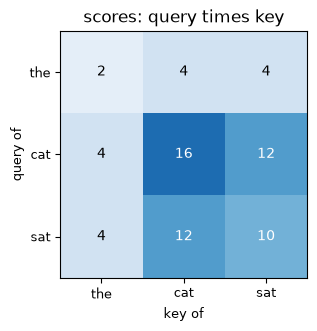

In [2]:
THE = [1, 0, 1, 0]
score_map(np.vstack([THE, X[1:]]))

### Solution

In [3]:
S, S_same = scores(X), scores(np.vstack([X[2], X[1:]]))
display(Markdown(f"The row of `cat` holds {S[1, 0]}, {S[1, 1]} and {S[1, 2]}: `cat` scores itself highest. The row of "
                 f"`the` holds {S[0, 0]}, {S[0, 1]} and {S[0, 2]}. With the vector of `sat`, `the` gets the same "
                 f"query and the same key as `sat`, so the first and last rows are equal, {tuple(int(v) for v in S_same[0])}, "
                 "and so are the first and last columns. The scores depend on the vectors alone."))

The row of `cat` holds 4, 16 and 12: `cat` scores itself highest. The row of `the` holds 2, 4 and 4. With the vector of `sat`, `the` gets the same query and the same key as `sat`, so the first and last rows are equal, (10, 12, 10), and so are the first and last columns. The scores depend on the vectors alone.

## 2. Dividing by the square root of 3 spreads the weights

Softmax turns each row of scores into weights that add to 1. With queries and
keys of width 3, the scores are first divided by the square root of 3.
Run the cell: what weight does `the` give itself? Then set `DIVIDE` to
`False` and run it again: how much weight does `cat` now put on itself?

output of the: (1.86, 6.32, 1.70)


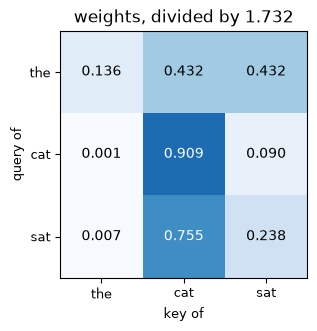

In [4]:
DIVIDE = True
weight_map(X, DIVIDE)

### Solution

In [5]:
A, A_raw = softmax_rows(scores(X) / np.sqrt(3)), softmax_rows(scores(X).astype(float))
display(Markdown(f"Divided by 1.732, `the` gives itself {A[0, 0]:.3f} and each other word {A[0, 1]:.3f}, and `cat` "
                 f"puts {A[1, 1]:.3f} on itself. Without the division `the` gives itself {A_raw[0, 0]:.3f} and `cat` "
                 f"puts {A_raw[1, 1]:.3f} on itself. The larger the scores, the closer softmax comes to putting all "
                 "the weight on one word. Wider queries and keys give larger scores, and dividing by the square root "
                 "of the width keeps their spread the same. GPT-2 Small's heads have width 64 and divide by 8."))

Divided by 1.732, `the` gives itself 0.136 and each other word 0.432, and `cat` puts 0.909 on itself. Without the division `the` gives itself 0.063 and `cat` puts 0.982 on itself. The larger the scores, the closer softmax comes to putting all the weight on one word. Wider queries and keys give larger scores, and dividing by the square root of the width keeps their spread the same. GPT-2 Small's heads have width 64 and divide by 8.